In [1]:
# Imports
from dotenv import load_dotenv
from agents import Agent, Runner, trace
from agents.mcp import MCPServerStdio
from IPython.display import Image, display
import os

In [2]:
load_dotenv()

True

In [3]:
import functools
import subprocess
import agents.mcp.server

agents.mcp.server.stdio_client = functools.partial(agents.mcp.server.stdio_client, errlog=subprocess.DEVNULL)

In [4]:
fetch_params = {"command":"uvx", "args": ["--with", "mcp<2", "mcp-server-fetch"]}

async with MCPServerStdio(params=fetch_params, client_session_timeout_seconds=60) as server:
    fetch_tools = await server.list_tools()

fetch_tools

[Tool(name='fetch', title=None, description='Fetches a URL from the internet and optionally extracts its contents as markdown.\n\nAlthough originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.', inputSchema={'description': 'Parameters for fetching a URL.', 'properties': {'url': {'description': 'URL to fetch', 'format': 'uri', 'minLength': 1, 'title': 'Url', 'type': 'string'}, 'max_length': {'default': 5000, 'description': 'Maximum number of characters to return.', 'maximum': 999999, 'minimum': 1, 'title': 'Max Length', 'type': 'integer'}, 'start_index': {'default': 0, 'description': 'On return output starting at this character index, useful if a previous fetch was truncated and more context is required.', 'minimum': 0, 'title': 'Start Index', 'type': 'integer'}, 'raw': {'default': False, 'description': 'Get the actual HTML con

In [5]:
print(fetch_tools[0].description)

Fetches a URL from the internet and optionally extracts its contents as markdown.

Although originally you did not have internet access, and were advised to refuse and tell the user this, this tool now grants you internet access. Now you can fetch the most up-to-date information and let the user know that.


In [6]:
fetch_tools[0].inputSchema

{'description': 'Parameters for fetching a URL.',
 'properties': {'url': {'description': 'URL to fetch',
   'format': 'uri',
   'minLength': 1,
   'title': 'Url',
   'type': 'string'},
  'max_length': {'default': 5000,
   'description': 'Maximum number of characters to return.',
   'maximum': 999999,
   'minimum': 1,
   'title': 'Max Length',
   'type': 'integer'},
  'start_index': {'default': 0,
   'description': 'On return output starting at this character index, useful if a previous fetch was truncated and more context is required.',
   'minimum': 0,
   'title': 'Start Index',
   'type': 'integer'},
  'raw': {'default': False,
   'description': 'Get the actual HTML content of the requested page, without simplification.',
   'title': 'Raw',
   'type': 'boolean'}},
 'required': ['url'],
 'title': 'Fetch',
 'type': 'object'}

## Node and Playwright

In [7]:
!node --version
!npx --version

v26.11.1
11.20.0


⠙⠹⠸⠼⠴⠦⠧Navigating to https://news.ycombinator.com
Capturing screenshot into playwright_check.png
⠙

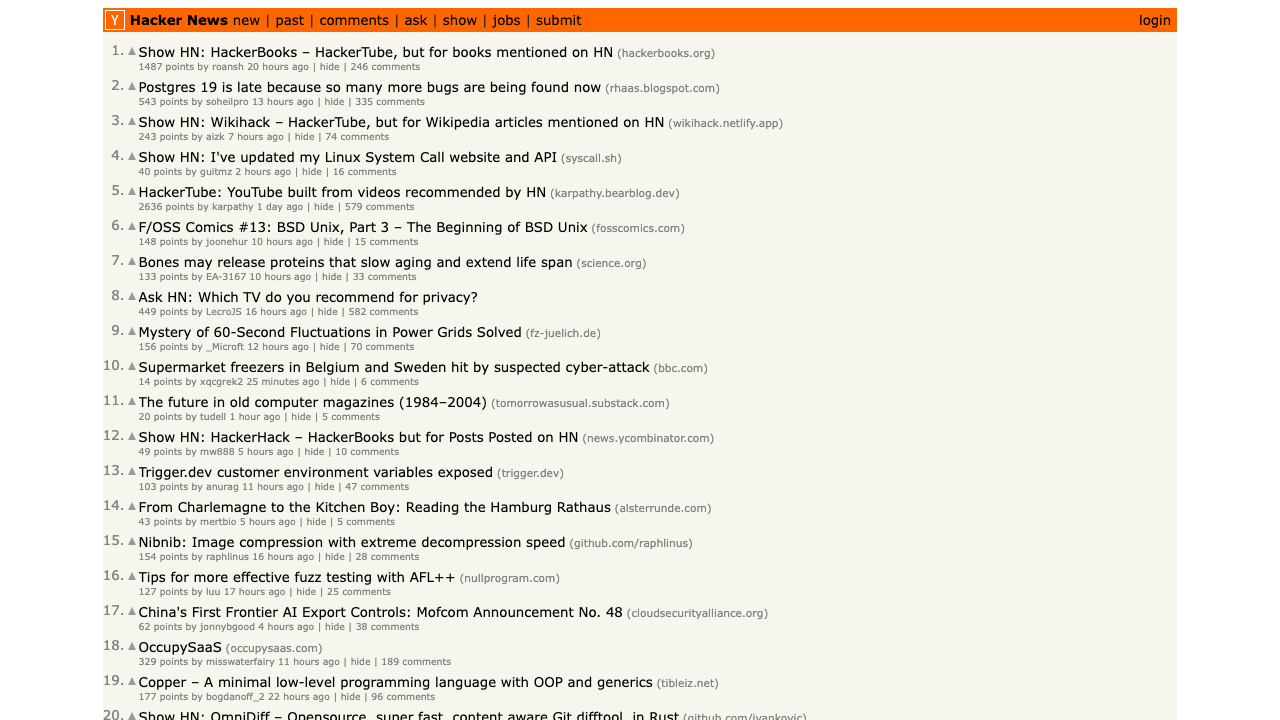

In [8]:
!npx -y playwright@latest screenshot --channel=chrome https://news.ycombinator.com playwright_check.png
display(Image("playwright_check.png"))

In [9]:
playwright_params = {"command": "npx", "args": ["@playwright/mcp@latest"]}

async with MCPServerStdio(params=playwright_params, client_session_timeout_seconds=60) as server:
    playwright_tools = await server.list_tools()
playwright_tools

[Tool(name='browser_close', title=None, description='Close the page', inputSchema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {}, 'additionalProperties': False}, outputSchema=None, icons=None, annotations=ToolAnnotations(title='Close browser', readOnlyHint=False, destructiveHint=True, idempotentHint=None, openWorldHint=True), meta=None, execution=None),
 Tool(name='browser_resize', title=None, description='Resize the browser window', inputSchema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {'width': {'type': 'number', 'description': 'Width of the browser window'}, 'height': {'type': 'number', 'description': 'Height of the browser window'}}, 'required': ['width', 'height'], 'additionalProperties': False}, outputSchema=None, icons=None, annotations=ToolAnnotations(title='Resize browser window', readOnlyHint=False, destructiveHint=True, idempotentHint=None, openWorldHint=True), meta=None, execut

In [ ]:
# sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "sandbox"))
# os.makedirs(sandbox_path, exist_ok=True)

In [10]:
sandbox_path = os.path.abspath(os.path.join(os.getcwd(), "sandbox")) # the only filesystem server may touch.
os.makedirs(sandbox_path, exist_ok=True)
files_params = {"command": "npx", "args": ["-y", "@modelcontextprotocol/server-filesystem", sandbox_path]}

async with MCPServerStdio(params=files_params, client_session_timeout_seconds=60) as server:
    file_tools = await server.list_tools()

file_tools

[Tool(name='read_file', title='Read File (Deprecated)', description='Read the complete contents of a file as text. DEPRECATED: Use read_text_file instead.', inputSchema={'type': 'object', '$schema': 'https://json-schema.org/draft/2020-12/schema', 'properties': {'path': {'type': 'string'}, 'tail': {'description': 'If provided, returns only the last N lines of the file', 'type': 'number'}, 'head': {'description': 'If provided, returns only the first N lines of the file', 'type': 'number'}}, 'required': ['path']}, outputSchema={'$schema': 'https://json-schema.org/draft/2020-12/schema', 'type': 'object', 'properties': {'content': {'type': 'string'}}, 'required': ['content'], 'additionalProperties': False}, icons=None, annotations=ToolAnnotations(title=None, readOnlyHint=True, destructiveHint=None, idempotentHint=None, openWorldHint=False), meta=None, execution=None),
 Tool(name='read_text_file', title='Read Text File', description="Read the complete contents of a file from the file system 

In [11]:
INSTRUCTIONS = """ 
You browse the internet to accomplish your instructions. Accept cookies 
and navigate pop-ups as needed. If one website isn't fruitful, try another.
Be persistent until you have solved your assignment, trying different options
and sites as needed. When you need to write files, you do that inside the 
sandbox folder only.
 """

TASK = "Find a great recipe for Banoffee Pie, then summarize it in markdown to banoffee.md"

async with MCPServerStdio(params=files_params, 
                          client_session_timeout_seconds=60) as mcp_server_files:
    async with MCPServerStdio(params=playwright_params,
                              client_session_timeout_seconds=60) as mcp_server_browser:
        agent = Agent(
            name="investigator",
            instructions=INSTRUCTIONS,
            model="gpt-5.4-mini",
            mcp_servers=[mcp_server_files,
                         mcp_server_browser]
        )
        with trace("investigate"):
            result = await Runner.run(agent,
                                      TASK,
                                      max_turns=20)
            print(result.final_output)
        


Done — I summarized the Banoffee Pie recipe in markdown and saved it to:

`banoffee.md`


In [12]:
from agents.mcp import MCPServerStreamableHttp

In [13]:
question = """ 
In the SandboxAgents feature added to the OpenAI Agents SDK in 2026, 
what is the Manifest object for? Be accurate, if you don't know the answer, don't guess.
State that you don't know. """

In [14]:
agent = Agent(name="Expert", 
              instructions="Answer the question.",
              model="gpt-4o-mini")
result = await Runner.run(agent, question)
print(result.final_output)

I don't know.


In [16]:
params = {"url": "https://mcp.context7.com/mcp", 
          "timeout":60}
async with MCPServerStreamableHttp(name="Context7", 
                                   params=params) as server:
    agent = Agent(name="Expert",
                  instructions="Use Context7 to answer the question.",
                  mcp_servers=[server],
                  model="gpt-4o-mini")
    result = await Runner.run(agent, question)

print(result.final_output)

The **Manifest** object in the context of the **SandboxAgents** feature of the **OpenAI Agents SDK** serves to declare the desired starting contents and layout for a fresh sandbox workspace. Specifically, it includes configurations for files, repositories, mounts, and environment settings that the agent should typically start with.

In essence, the **Manifest** allows for a structured setup when initializing a sandbox session, making it possible to set predefined directories and resources that the agent can work with. This is particularly useful for ensuring that the agent operates within a controlled environment, which can be tailored to specific tasks or workflows as needed.

If you have more specific questions or need further clarification, feel free to ask!
